# 01 – Environment Setup, Data Exploration and Preprocessing
**DS5007 NLP (Fall 2026) · Programming Assignment 2 · Transformer-Based Extractive Question Answering on SQuAD 1.1**

| Notebook | Content |
|---|---|
| **01_Data_Exploration** (this one) | environment, SQuAD 1.1 loading, exploratory data analysis, preprocessing (tokenisation, offsets, label alignment, truncation, sliding windows), metrics, pipeline verification |
| 02_Transformer_From_Scratch | Approach A1 – hand-written Transformer encoder + span heads, trained from random initialisation |
| 03_DistilBERT_Fine_Tuning | Approach A2 – pretrained DistilBERT + span heads, plain truncation |
| 04_DistilBERT_Sliding_Windows | Approach A3 – DistilBERT with overlapping windows; inference function and demos |
| 05_Experiments_and_Comparison | Experiments A–D (architecture, data size, sequence length, truncation), error analysis, final comparison |

All notebooks import **`eqa_lib.py`** (project root), so every approach uses exactly the same data pipeline, post-processing and metrics. The source of each library function is printed where it is first explained.

**Task.** Given a context paragraph $c$ and a question $q$, predict the start index $i$ and end index $j$ of the answer span inside $c$; the answer is the substring of the *original* paragraph covered by tokens $i..j$:
$$(\hat i, \hat j) = \arg\max_{i \le j} P_{\text{start}}(i \mid q, c)\, P_{\text{end}}(j \mid q, c).$$

## 1. Environment setup
Imports, reproducible seeds (`SEED = 42` for Python, NumPy and PyTorch; deterministic cuDNN), GPU/CPU detection and mixed-precision type.

In [1]:
# Environment: on Google Colab, mount Drive and work inside the uploaded project folder; locally nothing to do.
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = "/content/drive/MyDrive/EQA_Assignment"      # <- path of the uploaded project folder
    os.chdir(os.path.join(PROJECT_DIR, "notebooks"))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "transformers>=4.40", "datasets", "gradio"])
sys.path.insert(0, os.path.abspath(".."))                     # make eqa_lib.py (project root) importable

import eqa_lib as eqa          # imported first: it initialises OpenSSL before torch/pyarrow (Windows workaround)
import json, time, re, collections, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 120)
ENV = eqa.setup()

python         : 3.14.6
torch          : 2.14.1+cu126
transformers   : 5.19.0
numpy          : 2.4.6
pandas         : 3.0.3
device         : cuda
gpu            : NVIDIA GeForce RTX 4050 Laptop GPU
gpu_memory_gb  : 6.0
cuda           : 12.6
amp_dtype      : torch.bfloat16
seed           : 42
quick_run      : False
force_retrain  : False
project_root   : C:\Users\kiran\NLP Assignment 2\EQA_Assignment


In [2]:
eqa.show_source(eqa.set_seed)
print('Configuration shared by all notebooks:'); print(json.dumps(eqa.CFG, indent=2))

```python
def set_seed(seed: int = SEED) -> None:
    """Seed Python, NumPy and PyTorch (CPU + all GPUs) and make cuDNN deterministic."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

```

Configuration shared by all notebooks:
{
  "max_length": 384,
  "doc_stride": 128,
  "max_question_tokens": 64,
  "max_answer_length": 30,
  "n_best": 20,
  "eval_batch_size": 64
}


## 2. Dataset loading
SQuAD 1.1 is loaded with **Hugging Face Datasets** (`load_dataset("rajpurkar/squad")`). If `datasets` cannot be imported (on the development PC a Windows *Application Control* policy blocks one of its compiled dependencies), `eqa.load_squad` downloads the **same parquet files** from the Hugging Face Hub, so both paths give identical data.

Each record: `id`, `title` (Wikipedia article), `context` (paragraph), `question`, and `answers = {text: [...], answer_start: [...]}`, where `answer_start` is a **character** offset into the context. We flatten `answers` into two list columns, `answer_texts` and `answer_starts`.

In [3]:
eqa.show_source(eqa.load_squad)
train_raw, val_df, DATA_SOURCE = eqa.load_squad()
train_raw.head(3)

```python
def load_squad(quick: bool = QUICK_RUN, verbose: bool = True):
    """Load SQuAD 1.1 (train, validation) as DataFrames with list columns `answer_texts` / `answer_starts`.

    Uses Hugging Face Datasets; if that package cannot be imported (on the development PC a Windows Application
    Control policy blocks one of its compiled dependencies) the identical parquet files that `load_dataset` reads
    are downloaded from the Hugging Face Hub instead.
    """
    try:
        from datasets import load_dataset
        ds = load_dataset("rajpurkar/squad")
        train_df, val_df = ds["train"].to_pandas(), ds["validation"].to_pandas()
        source = "datasets.load_dataset('rajpurkar/squad')"
    except Exception as exc:
        if verbose:
            print(f"[info] `datasets` not usable here ({type(exc).__name__}: {str(exc)[:80]}...)")
            print("[info] Falling back to the identical parquet files on the Hugging Face Hub.")
        from huggingface_hub import hf_hub_download
        frames = {}
        for split in ("train", "validation"):
            path = hf_hub_download("rajpurkar/squad", f"plain_text/{split}-00000-of-00001.parquet", repo_type="dataset")
            frames[split] = pd.read_parquet(path)
        train_df, val_df = frames["train"], frames["validation"]
        source = "huggingface_hub: rajpurkar/squad (plain_text parquet)"
    for df in (train_df, val_df):
        df["answer_texts"] = [[str(t) for t in a["text"]] for a in df["answers"]]
        df["answer_starts"] = [[int(s) for s in a["answer_start"]] for a in df["answers"]]
        df.drop(columns="answers", inplace=True)
    train_df, val_df = train_df.reset_index(drop=True), val_df.reset_index(drop=True)
    if quick:
        train_df = train_df.sample(800, random_state=SEED).reset_index(drop=True)
        val_df = val_df.sample(300, random_state=SEED).reset_index(drop=True)
    if verbose:
        print(f"Loaded from {source}: {len(train_df):,} training / {len(val_df):,} validation examples")
    return train_df, val_df, source

```

[info] `datasets` not usable here (ImportError: DLL load failed while importing _xxhash: An Application Control policy has block...)
[info] Falling back to the identical parquet files on the Hugging Face Hub.


Loaded from huggingface_hub: rajpurkar/squad (plain_text parquet): 87,599 training / 10,570 validation examples


,id,title,context,question,answer_texts,answer_starts
0,5733be284776f41900661182,University_of_Notre_Dame,"Architecturally, the school has a Catholic character. Atop the Main Building's gold dome is a golden statue of the V...",To whom did the Virgin Mary allegedly appear in 1858 in Lourdes France?,[Saint Bernadette Soubirous],[515]
1,5733be284776f4190066117f,University_of_Notre_Dame,"Architecturally, the school has a Catholic character. Atop the Main Building's gold dome is a golden statue of the V...",What is in front of the Notre Dame Main Building?,[a copper statue of Christ],[188]
2,5733be284776f41900661180,University_of_Notre_Dame,"Architecturally, the school has a Catholic character. Atop the Main Building's gold dome is a golden statue of the V...",The Basilica of the Sacred heart at Notre Dame is beside to which structure?,[the Main Building],[279]


In [4]:
def show_example(row, max_ctx_chars=500):
    ctx = row["context"]
    print(f"Title    : {row['title']}")
    print(f"Context  : {ctx[:max_ctx_chars]}{' ...' if len(ctx) > max_ctx_chars else ''}")
    print(f"Question : {row['question']}")
    for t, s in zip(row["answer_texts"], row["answer_starts"]):
        print(f"Answer   : {t!r:35} answer_start={s:<5} context[{s}:{s + len(t)}] = {ctx[s:s + len(t)]!r}")
    print("-" * 110)

show_example(train_raw.iloc[0])
print("Validation example – several annotators give several reference answers:")
show_example(val_df.iloc[3])

overview = pd.DataFrame({
    split: {"examples (questions)": len(df), "unique contexts": df["context"].nunique(),
            "unique articles": df["title"].nunique(),
            "questions per context": round(len(df) / df["context"].nunique(), 2),
            "mean reference answers per question": round(df["answer_texts"].apply(len).mean(), 2)}
    for split, df in [("train", train_raw), ("validation", val_df)]})
overview

Title    : University_of_Notre_Dame
Context  : Architecturally, the school has a Catholic character. Atop the Main Building's gold dome is a golden statue of the Virgin Mary. Immediately in front of the Main Building and facing it, is a copper statue of Christ with arms upraised with the legend "Venite Ad Me Omnes". Next to the Main Building is the Basilica of the Sacred Heart. Immediately behind the basilica is the Grotto, a Marian place of prayer and reflection. It is a replica of the grotto at Lourdes, France where the Virgin Mary reputed ...
Question : To whom did the Virgin Mary allegedly appear in 1858 in Lourdes France?
Answer   : 'Saint Bernadette Soubirous'        answer_start=515   context[515:541] = 'Saint Bernadette Soubirous'
--------------------------------------------------------------------------------------------------------------
Validation example – several annotators give several reference answers:
Title    : Super_Bowl_50
Context  : Super Bowl 50 was an American fo

,train,validation
examples (questions),87599.00,10570.00
unique contexts,18891.00,2067.00
unique articles,442.00,48.00
questions per context,4.64,5.11
mean reference answers per question,1.00,3.29


**Structure.** Several questions share a paragraph (≈4.6 per context), so there are far fewer unique contexts than questions. Training questions have one answer; validation questions have ≈3 answers from different crowd-workers (often identical or differing only in boundaries, e.g. *"Denver Broncos"* vs *"the Denver Broncos"*), and the metrics take the maximum over them. The official test set is hidden, so the validation set is our evaluation set.

## 3. Exploratory data analysis
### 3.1 Data quality
Missing values, empty strings, duplicates and – most importantly – whether every `answer_start` really points at the answer text (`context[start : start + len(text)] == text`). Inconsistent training answers would be repaired (nearest occurrence of the text) or dropped by `eqa.clean_training_data`.

In [5]:
def quality_report(df):
    ok = bad = 0
    for ctx, texts, starts in zip(df["context"], df["answer_texts"], df["answer_starts"]):
        for t, s in zip(texts, starts):
            ok, bad = (ok + 1, bad) if ctx[s:s + len(t)] == t else (ok, bad + 1)
    return {"missing values": int(df[["id", "title", "context", "question"]].isna().sum().sum()),
            "empty questions": int((df["question"].str.strip() == "").sum()),
            "empty contexts": int((df["context"].str.strip() == "").sum()),
            "questions without answer": int((df["answer_texts"].apply(len) == 0).sum()),
            "empty answer strings": int(sum(any(t.strip() == "" for t in a) for a in df["answer_texts"])),
            "duplicate (question, context) pairs": int(df.duplicated(subset=["question", "context"]).sum()),
            "answers with consistent answer_start": ok, "answers with INconsistent answer_start": bad,
            "questions with leading/trailing whitespace": int((df["question"] != df["question"].str.strip()).sum())}

display(pd.DataFrame({"train": quality_report(train_raw), "validation": quality_report(val_df)}))
eqa.show_source(eqa.fix_answer_start)
train_df, status = eqa.clean_training_data(train_raw)
print("Training answer offsets:", status, f"-> {len(train_df):,} training examples kept")
val_df["n_distinct_answers"] = [len({eqa.normalize_answer(t) for t in a}) for a in val_df["answer_texts"]]
print("\nValidation questions by number of DIFFERENT (normalised) reference answers (annotator disagreement):")
print(val_df["n_distinct_answers"].value_counts().sort_index().to_string())

,train,validation
missing values,0,0
empty questions,0,0
empty contexts,0,0
questions without answer,0,0
empty answer strings,0,0
"duplicate (question, context) pairs",166,29
answers with consistent answer_start,87599,34726
answers with INconsistent answer_start,0,0
questions with leading/trailing whitespace,3054,344


```python
def fix_answer_start(context: str, text: str, start: int):
    """Return (start, status). Repairs an answer_start that does not point at the answer text."""
    if context[start:start + len(text)] == text:
        return start, "ok"
    occurrences = [m.start() for m in re.finditer(re.escape(text), context)]
    if occurrences:
        return min(occurrences, key=lambda o: abs(o - start)), "repaired"
    return None, "invalid"

```

Training answer offsets: {'ok': 87599} -> 87,599 training examples kept



Validation questions by number of DIFFERENT (normalised) reference answers (annotator disagreement):
n_distinct_answers
1    5915
2    3606
3     910
4     117
5      22


### 3.2 Lengths of contexts, questions and answers

In [6]:
t0 = time.time()
tokenizer = eqa.get_tokenizer()
train_df = eqa.add_eda_columns(train_df, tokenizer)
val_df = eqa.add_eda_columns(val_df, tokenizer)
print(f"EDA columns computed in {time.time() - t0:.0f}s")
cols = ["context_words", "context_tokens", "question_words", "question_tokens", "answer_words"]
pd.concat({"train": train_df[cols].describe().T, "validation": val_df[cols].describe().T}).round(1)

EDA columns computed in 23s


count   mean   std   min    25%    50%    75%  \
train      context_words    87599.0  119.8  49.4  20.0   89.0  110.0  142.0   
           context_tokens   87599.0  155.8  65.1  25.0  114.0  143.0  185.0   
           question_words   87599.0   10.1   3.6   1.0    8.0   10.0   12.0   
           question_tokens  87599.0   12.3   4.1   1.0    9.0   12.0   14.0   
           answer_words     87599.0    3.2   3.4   1.0    1.0    2.0    3.0   
validation context_words    10570.0  124.0  56.1  22.0   91.0  112.0  146.0   
           context_tokens   10570.0  161.0  72.7  30.0  117.0  147.0  188.0   
           question_words   10570.0   10.2   3.6   3.0    8.0   10.0   12.0   
           question_tokens  10570.0   12.6   4.1   4.0   10.0   12.0   15.0   
           answer_words     10570.0    3.0   3.0   1.0    1.0    2.0    3.0   

                              max  
train      context_words    653.0  
           context_tokens   853.0  
           question_words    40.0  
           question_tokens   61.0  
           answer_words      43.0  
validation context_words    629.0  
           context_tokens   789.0  
           question_words    33.0  
           question_tokens   38.0  
           answer_words      29.0

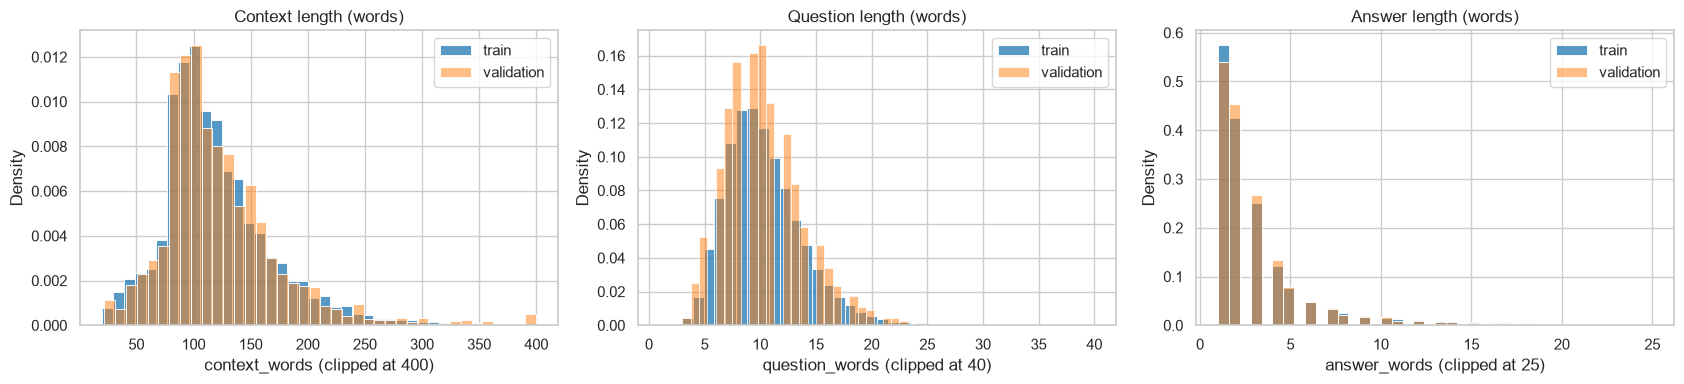

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, col, title, clip in zip(axes, ["context_words", "question_words", "answer_words"],
                                ["Context length (words)", "Question length (words)", "Answer length (words)"], [400, 40, 25]):
    sns.histplot(train_df[col].clip(upper=clip), bins=40, stat="density", ax=ax, label="train", color="#1f77b4")
    sns.histplot(val_df[col].clip(upper=clip), bins=40, stat="density", ax=ax, label="validation", color="#ff7f0e", alpha=0.5)
    ax.set_title(title); ax.set_xlabel(f"{col} (clipped at {clip})"); ax.legend()
eqa.savefig("01_length_distributions")

,max_length (tokens),train: % pairs longer than L,validation: % pairs longer than L
0,128,75.84,78.63
1,256,9.63,11.10
2,384,1.02,1.73
3,512,0.13,0.53


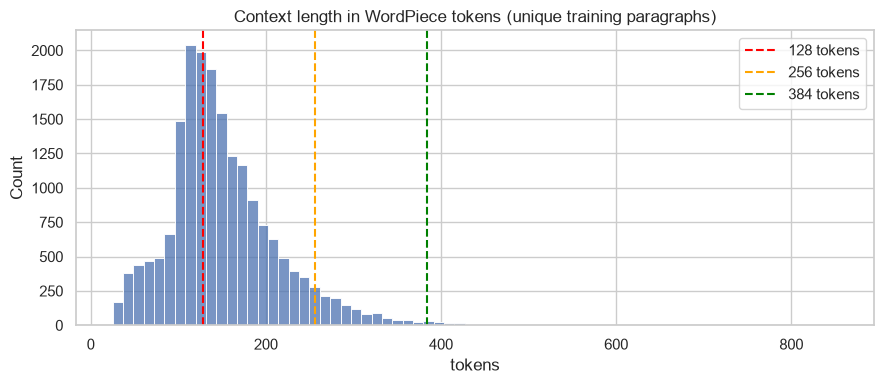

In [8]:
# The model sees WordPiece tokens, so input limits are about tokens: how many pairs do not fit?
limits = (128, 256, 384, 512)
fit_tbl = pd.DataFrame([{"max_length (tokens)": L,
                         "train: % pairs longer than L": 100 * (train_df["pair_tokens"] > L).mean(),
                         "validation: % pairs longer than L": 100 * (val_df["pair_tokens"] > L).mean()} for L in limits]).round(2)
display(fit_tbl)
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(train_df.drop_duplicates("context")["context_tokens"], bins=70, ax=ax)
for L, c in zip(limits[:3], ["red", "orange", "green"]):
    ax.axvline(L, color=c, ls="--", label=f"{L} tokens")
ax.set_title("Context length in WordPiece tokens (unique training paragraphs)"); ax.set_xlabel("tokens"); ax.legend()
eqa.savefig("01_context_token_lengths")

### 3.3 Where are the answers, and what is asked?

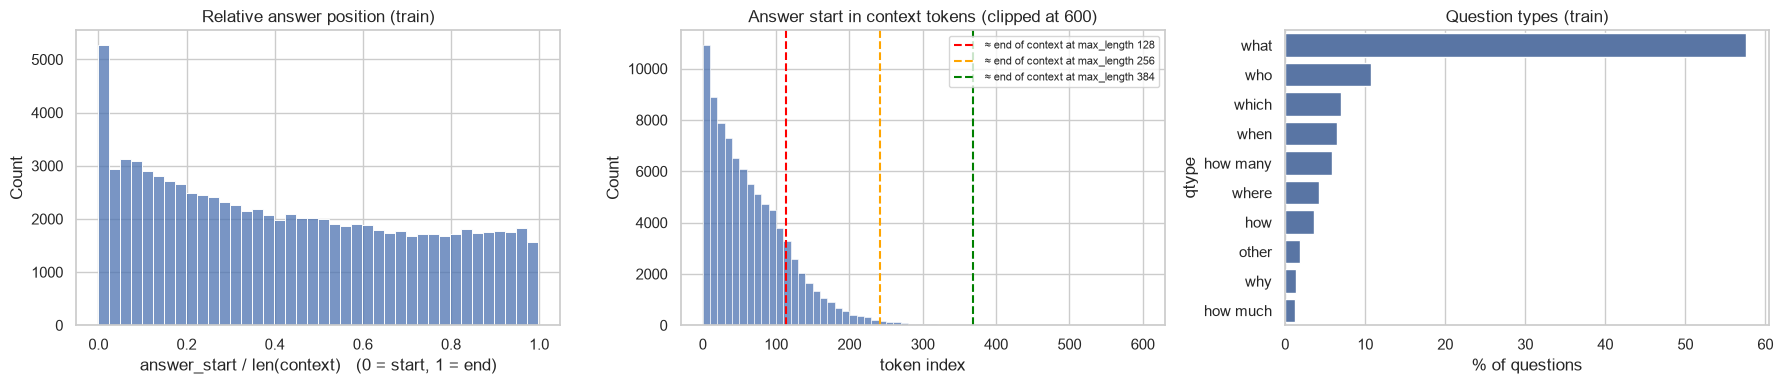

Answers starting in the first half of the paragraph: 59.4%
Answers starting after token 125 / 253 / 381 of the context (cut by truncation at 128 / 256 / 384 incl. question): 17.4% / 1.0% / 0.1%


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
sns.histplot(train_df["answer_rel_pos"], bins=40, ax=axes[0])
axes[0].set_title("Relative answer position (train)"); axes[0].set_xlabel("answer_start / len(context)   (0 = start, 1 = end)")
sns.histplot(train_df["answer_start_token_in_context"].clip(upper=600), bins=60, ax=axes[1])
for L, c in [(128, "red"), (256, "orange"), (384, "green")]:
    axes[1].axvline(L - 3 - train_df["question_tokens"].median(), color=c, ls="--", label=f"≈ end of context at max_length {L}")
axes[1].set_title("Answer start in context tokens (clipped at 600)"); axes[1].set_xlabel("token index"); axes[1].legend(fontsize=8)
qt = train_df["qtype"].value_counts(normalize=True) * 100
sns.barplot(x=qt.values, y=qt.index, ax=axes[2], orient="h")
axes[2].set_title("Question types (train)"); axes[2].set_xlabel("% of questions")
eqa.savefig("01_answer_position_and_question_types")
print(f"Answers starting in the first half of the paragraph: {(train_df['answer_rel_pos'] < 0.5).mean():.1%}")
print(f"Answers starting after token 125 / 253 / 381 of the context (cut by truncation at 128 / 256 / 384 incl. question): "
      + " / ".join(f"{(train_df['answer_start_token_in_context'] > L - 3 - train_df['question_tokens']).mean():.1%}" for L in (128, 256, 384)))

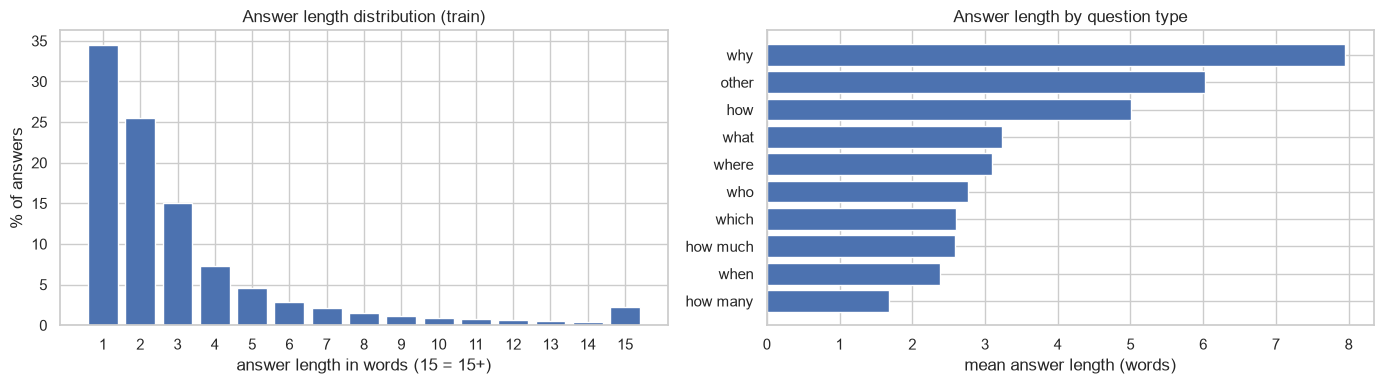

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
ans_len = train_df["answer_words"].clip(upper=15).value_counts(normalize=True).sort_index() * 100
axes[0].bar(ans_len.index.astype(str), ans_len.values); axes[0].set_xlabel("answer length in words (15 = 15+)")
axes[0].set_ylabel("% of answers"); axes[0].set_title("Answer length distribution (train)")
by_q = train_df.groupby("qtype")["answer_words"].mean().sort_values()
axes[1].barh(by_q.index, by_q.values); axes[1].set_xlabel("mean answer length (words)"); axes[1].set_title("Answer length by question type")
eqa.savefig("01_answer_lengths")

### 3.4 Examples of short and long contexts

In [11]:
uniq = train_df.drop_duplicates("context")
short_row = train_df[train_df["context"] == uniq.nsmallest(1, "context_tokens")["context"].iloc[0]].iloc[0]
long_row = train_df[train_df["context"] == uniq.nlargest(1, "context_tokens")["context"].iloc[0]].iloc[0]
med_ctx = uniq.iloc[(uniq["context_tokens"] - uniq["context_tokens"].median()).abs().argsort().iloc[0]]["context"]
med_row = train_df[train_df["context"] == med_ctx].iloc[0]
for name, row in [("SHORTEST", short_row), ("MEDIAN-LENGTH", med_row), ("LONGEST", long_row)]:
    print(f"=== {name} context: {row['context_tokens']} tokens / {row['context_words']} words ===")
    show_example(row, max_ctx_chars=700)

=== SHORTEST context: 25 tokens / 23 words ===
Title    : 2008_Summer_Olympics_torch_relay
Context  : Two additional teams of 40 attendants each will accompany the flame on its Mainland China route. This arrangement has however sparked several controversies.
Question : How many additional teams will help with the Mainland China route?
Answer   : 'Two'                               answer_start=0     context[0:3] = 'Two'
--------------------------------------------------------------------------------------------------------------
=== MEDIAN-LENGTH context: 140 tokens / 103 words ===
Title    : Copper
Context  : The gates of the Temple of Jerusalem used Corinthian bronze made by depletion gilding. It was most prevalent in Alexandria, where alchemy is thought to have begun. In ancient India, copper was used in the holistic medical science Ayurveda for surgical instruments and other medical equipment. Ancient Egyptians (~2400 BC) used copper for sterilizing wounds and drinking water, and l

In [12]:
eda_summary = {
    "data_source": DATA_SOURCE,
    "train_examples": len(train_df), "validation_examples": len(val_df),
    "train_unique_contexts": int(train_df["context"].nunique()), "validation_unique_contexts": int(val_df["context"].nunique()),
    "train_articles": int(train_df["title"].nunique()), "validation_articles": int(val_df["title"].nunique()),
    "offset_status_train": status,
    "means_train": train_df[cols].mean().round(2).to_dict(), "means_validation": val_df[cols].mean().round(2).to_dict(),
    "answer_words_median": float(train_df["answer_words"].median()),
    "pct_answers_first_half_train": float(100 * (train_df["answer_rel_pos"] < 0.5).mean()),
    "pct_pairs_longer_than": {int(r["max_length (tokens)"]): {"train": r["train: % pairs longer than L"],
                                                              "validation": r["validation: % pairs longer than L"]}
                              for _, r in fit_tbl.iterrows()},
    "validation_ref_answers_mean": float(val_df["answer_texts"].apply(len).mean()),
    "validation_pct_questions_with_disagreement": float(100 * (val_df["n_distinct_answers"] > 1).mean()),
    "question_types_train_pct": qt.round(2).to_dict(),
}
eqa.save_json(eda_summary, eqa.PATHS.results / "eda_summary.json")
print(json.dumps(eda_summary, indent=1)[:1500])

{
 "data_source": "huggingface_hub: rajpurkar/squad (plain_text parquet)",
 "train_examples": 87599,
 "validation_examples": 10570,
 "train_unique_contexts": 18891,
 "validation_unique_contexts": 2067,
 "train_articles": 442,
 "validation_articles": 48,
 "offset_status_train": {
  "ok": 87599
 },
 "means_train": {
  "context_words": 119.76,
  "context_tokens": 155.75,
  "question_words": 10.06,
  "question_tokens": 12.29,
  "answer_words": 3.16
 },
 "means_validation": {
  "context_words": 123.95,
  "context_tokens": 161.0,
  "question_words": 10.22,
  "question_tokens": 12.57,
  "answer_words": 3.02
 },
 "answer_words_median": 2.0,
 "pct_answers_first_half_train": 59.40935398805922,
 "pct_pairs_longer_than": {
  "128": {
   "train": 75.84,
   "validation": 78.63
  },
  "256": {
   "train": 9.63,
   "validation": 11.1
  },
  "384": {
   "train": 1.02,
   "validation": 1.73
  },
  "512": {
   "train": 0.13,
   "validation": 0.53
  }
 },
 "validation_ref_answers_mean": 3.285335856196783,

### 3.5 EDA findings and their consequences for the design
* **Short answers, long contexts.** Most answers are 1–3 words, while contexts average ≈120 words (≈155 tokens). A maximum answer length of 30 tokens at inference loses almost nothing.
* **Input length matters.** Only ≈1% of question–context pairs exceed 384 tokens, but ≈10% exceed 256 and ≈76% exceed 128 tokens (table above). With **truncation**, every answer after the cut becomes unreachable. This motivates **Approach A3 (sliding windows)** and Experiments C/D.
* **Answer position.** Answers appear throughout the paragraph, somewhat more often in the first half, so a model cannot rely on position. Truncation hurts exactly the questions whose answers lie late in long paragraphs.
* **Question types.** "What" dominates. "When"/"how many" questions have date/number answers and "who" questions have names; these categories are analysed separately in the error analysis (notebook 05).
* **Data quality.** There are no missing values, no empty fields and no inconsistent `answer_start` offsets. 166 training questions are exact (question, context) duplicates; they are harmless and kept. About 3,000 questions have stray leading/trailing spaces, which we strip. In the validation set, 44% of questions have at least two different normalised reference answers. The disagreement is mostly about span boundaries, which is why F1 is reported alongside EM.

## 4. Preprocessing
### 4.1 Tokenisation, special tokens, token type ids, attention mask and offsets
We use the **uncased WordPiece tokenizer** (`bert-base-uncased`, the *same* 30,522-token vocabulary as `distilbert-base-uncased`). It is shared by all three approaches, so they see identical inputs. A question–context pair becomes

`[CLS] question tokens [SEP] context tokens [SEP]`

* `[CLS]` (id 101) starts the sequence; we also use its position (index 0) as the label "answer not in this input".
* `[SEP]` (id 102) separates and ends the two segments. `[PAD]` (id 0) fills short sequences in a batch.
* **token_type_ids** (segment ids): 0 for `[CLS] question [SEP]`, 1 for `context [SEP]`. DistilBERT has no segment embeddings, so these are only passed to models that use them (A1).
* **attention_mask**: 1 for real tokens, 0 for padding, so padding receives no attention.
* **offset_mapping**: for every token, the `(char_start, char_end)` it covers in the original string. This is the only correct bridge between the **character** offsets of SQuAD answers and the **token** positions the model predicts.

In [13]:
demo_context = ("Alan Turing was a British mathematician and computer scientist. "
                "He introduced the concept of the Turing machine in 1936.")
demo_question = "In which year did Alan Turing introduce the Turing machine?"
enc = tokenizer(demo_question, demo_context, return_offsets_mapping=True)
token_table = pd.DataFrame({"token": tokenizer.convert_ids_to_tokens(enc["input_ids"]), "input_id": enc["input_ids"],
                            "token_type_id": enc["token_type_ids"], "attention_mask": enc["attention_mask"],
                            "sequence_id": enc.sequence_ids(), "char_offsets": [tuple(o) for o in enc["offset_mapping"]]})
print("Special tokens:", {t: tokenizer.convert_tokens_to_ids(t) for t in ["[CLS]", "[SEP]", "[PAD]", "[UNK]"]})
display(token_table.T)

ans = "1936"
start_char = demo_context.index(ans); end_char = start_char + len(ans)
seq_ids, offs = enc.sequence_ids(), enc["offset_mapping"]
start_tok = next(i for i, (s, o) in enumerate(zip(seq_ids, offs)) if s == 1 and o[0] <= start_char < o[1])
end_tok = next(i for i, (s, o) in enumerate(zip(seq_ids, offs)) if s == 1 and o[0] < end_char <= o[1])
print(f"Answer {ans!r}: characters [{start_char}, {end_char})  ->  tokens [{start_tok}, {end_tok}] "
      f"{tokenizer.convert_ids_to_tokens(enc['input_ids'][start_tok:end_tok + 1])}  ->  back to text via offsets: "
      f"{demo_context[offs[start_tok][0]:offs[end_tok][1]]!r}")
print(f"The character index ({start_char}) and the token index ({start_tok}) are unrelated: they must be mapped with offsets.")

Special tokens: {'[CLS]': 101, '[SEP]': 102, '[PAD]': 0, '[UNK]': 100}


,0,1,2,3,4,5,6,7,8,9,...,25,26,27,28,29,30,31,32,33,34
token,[CLS],in,which,year,did,alan,turing,introduce,the,turing,...,the,concept,of,the,turing,machine,in,1936,.,[SEP]
input_id,101,1999,2029,2095,2106,5070,28639,8970,1996,28639,...,1996,4145,1997,1996,28639,3698,1999,4266,1012,102
token_type_id,0,0,0,0,0,0,0,0,0,0,...,1,1,1,1,1,1,1,1,1,1
attention_mask,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
sequence_id,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN
char_offsets,"(0, 0)","(0, 2)","(3, 8)","(9, 13)","(14, 17)","(18, 22)","(23, 29)","(30, 39)","(40, 43)","(44, 50)",...,"(78, 81)","(82, 89)","(90, 92)","(93, 96)","(97, 103)","(104, 111)","(112, 114)","(115, 119)","(119, 120)","(0, 0)"


Answer '1936': characters [115, 119)  ->  tokens [32, 32] ['1936']  ->  back to text via offsets: '1936'
The character index (115) and the token index (32) are unrelated: they must be mapped with offsets.


### 4.2 Label generation, truncation and sliding windows
`eqa.prepare_features` turns each example into one or more **features** (model inputs) and creates the labels:

1. **Pair construction:** strip the question and cap it at 64 tokens (so short inputs still leave room for context); tokenise `(question, context)` with `truncation="only_second"` so the question is never cut.
2. **Truncation (A2):** keep only the first `max_length` tokens, giving one feature per example.
   **Sliding windows (A3):** `return_overflowing_tokens=True, stride=doc_stride` gives several overlapping windows per long context; `overflow_to_sample_mapping` tells which example each window belongs to.
3. **Character → token alignment:** find the window's first and last context token (`sequence_ids == 1`). If the gold span `[answer_start, answer_start + len(text))` lies entirely inside, the start label is the last token whose start offset ≤ `answer_start` and the end label is the first token whose end offset ≥ `answer_end`.
4. **Windows/inputs without the answer** (answer cut away or in another window) are labelled `(0, 0)` = `[CLS]`.
5. **Verification:** every label is checked by cutting `context[offset(start).start : offset(end).end]` and comparing it with the gold text.
6. For evaluation we keep the offsets, set to `None` for non-context tokens, so a prediction can never point into the question.

In [14]:
eqa.show_source(eqa.truncate_questions, eqa.prepare_features)

```python
def truncate_questions(questions, tokenizer, max_tokens):
    """Strip questions and cut the rare very long ones to `max_tokens` WordPiece tokens."""
    questions = [q.strip() for q in questions]
    enc = tokenizer(questions, add_special_tokens=False, return_offsets_mapping=True)
    out, n_cut = [], 0
    for q, offs in zip(questions, enc["offset_mapping"]):
        if len(offs) > max_tokens:
            q, n_cut = q[:offs[max_tokens - 1][1]], n_cut + 1
        out.append(q)
    return out, n_cut

```

```python
def prepare_features(df, tokenizer=None, max_length=384, doc_stride=128, sliding_window=True,
                     keep_offsets=False, chunk_size=2000):
    """Tokenise (question, context) pairs and create token-level start/end labels.

    sliding_window=True  -> long contexts become several overlapping windows (`doc_stride` tokens of overlap)
    sliding_window=False -> plain truncation: only the first `max_length` tokens are kept (one feature per example)

    Label rule for each feature: if the gold answer [start_char, end_char) lies completely inside the feature's
    context tokens, start = last token starting at/before start_char and end = first token ending at/after
    end_char; otherwise both labels are 0 (the [CLS] token = "answer not in this window").
    Returns (feats: dict of per-feature lists, stats: alignment diagnostics).
    """
    tokenizer = tokenizer or get_tokenizer()
    questions, n_cut = truncate_questions(df["question"].tolist(), tokenizer, CFG["max_question_tokens"])
    contexts = df["context"].tolist()
    ans_texts = [a[0] for a in df["answer_texts"]]
    ans_starts = [s[0] for s in df["answer_starts"]]

    keys = ["input_ids", "token_type_ids", "start_positions", "end_positions", "example_idx", "window_idx"]
    feats = {k: [] for k in keys + (["offset_mapping"] if keep_offsets else [])}
    stats = collections.Counter(questions_truncated=n_cut)
    examples_with_answer, mismatches = set(), []

    for c0 in range(0, len(df), chunk_size):
        enc = tokenizer(questions[c0:c0 + chunk_size], contexts[c0:c0 + chunk_size],
                        truncation="only_second",                 # never cut the question, only the context
                        max_length=max_length,
                        stride=doc_stride if sliding_window else 0,
                        return_overflowing_tokens=sliding_window,  # several windows per long context
                        return_offsets_mapping=True,               # char span of every token
                        return_token_type_ids=True,
                        padding=False)                             # dynamic padding later, per batch
        sample_map = enc["overflow_to_sample_mapping"] if sliding_window else list(range(len(enc["input_ids"])))
        prev_ex, window = -1, 0
        for i, input_ids in enumerate(enc["input_ids"]):
            ex = c0 + sample_map[i]
            window = window + 1 if ex == prev_ex else 0
            prev_ex = ex
            seq_ids, offsets = enc.sequence_ids(i), enc["offset_mapping"][i]
            ctx_first = seq_ids.index(1)
            ctx_last = len(seq_ids) - 1 - seq_ids[::-1].index(1)

            start_char = ans_starts[ex]
            end_char = start_char + len(ans_texts[ex])
            if start_char < 0 or offsets[ctx_first][0] > start_char or offsets[ctx_last][1] < end_char:
                start_pos = end_pos = 0
                stats["windows_without_answer"] += 1
            else:
                start_pos = ctx_first
                while start_pos <= ctx_last and offsets[start_pos][0] <= start_char:
                    start_pos += 1
                start_pos -= 1
                end_pos = ctx_last
                while end_pos >= ctx_first and offsets[end_pos][1] >= end_char:
                    end_pos -= 1
                end_pos += 1
                stats["windows_with_answer"] += 1
                examples_with_answer.add(ex)
                recovered = contexts[ex][offsets[start_pos][0]:offsets[end_pos][1]]
                if recovered == ans_texts[ex]:
                    stats["span_exact_match"] += 1
                elif normalize_answer(recovered) == normalize_answer(ans_texts[ex]):
                    stats["span_normalized_match"] += 1
                else:
                    stats["span_mismatch"] += 1
                    if len(mismatches) < 8:
                        mismatches.append((ans_texts[ex], recovered))

            feats["input_ids"].append(input_ids)
            feats["token_type_ids"].append(enc["token_type_ids"][i])
            feats["start_positions"].append(start_pos)
            feats["end_positions"].append(end_pos)
            feats["example_idx"].append(ex)
            feats["window_idx"].append(window)
            if keep_offsets:
                feats["offset_mapping"].append([tuple(o) if seq_ids[k] == 1 else None for k, o in enumerate(offsets)])

    stats["examples"] = len(df)
    stats["features"] = len(feats["input_ids"])
    stats["examples_with_answer_in_some_window"] = len(examples_with_answer)
    stats["examples_whose_answer_is_unreachable"] = len(df) - len(examples_with_answer)
    stats = dict(stats)
    stats["mismatch_examples"] = mismatches
    return feats, stats

```

In [15]:
t0 = time.time()
train_win, train_win_stats = eqa.prepare_features(train_df, tokenizer, 384, 128, sliding_window=True)
train_trunc, train_trunc_stats = eqa.prepare_features(train_df, tokenizer, 384, sliding_window=False)
val_win, val_win_stats = eqa.prepare_features(val_df, tokenizer, 384, 128, sliding_window=True, keep_offsets=True)
val_trunc, val_trunc_stats = eqa.prepare_features(val_df, tokenizer, 384, sliding_window=False, keep_offsets=True)
print(f"Feature preparation: {time.time() - t0:.0f}s")
stats_tbl = pd.DataFrame({"train – windows 384/128": train_win_stats, "train – truncation 384": train_trunc_stats,
                          "val – windows 384/128": val_win_stats, "val – truncation 384": val_trunc_stats}).drop(index="mismatch_examples")
display(stats_tbl)
aligned = train_win_stats.get("span_exact_match", 0) + train_win_stats.get("span_normalized_match", 0)
print(f"Alignment check: {100 * aligned / train_win_stats['windows_with_answer']:.3f}% of training windows that contain the answer "
      f"reproduce the gold text from the token labels ({train_win_stats.get('span_exact_match', 0):,} exactly, "
      f"{train_win_stats.get('span_normalized_match', 0):,} after normalisation, {train_win_stats.get('span_mismatch', 0):,} mismatches).")
print("Mismatches (gold text vs text recovered from the token span):")
for gold, rec in train_win_stats["mismatch_examples"]:
    print(f"   gold={gold!r:45} recovered={rec!r}")

Feature preparation: 67s


,train – windows 384/128,train – truncation 384,val – windows 384/128,val – truncation 384
questions_truncated,0,0,0,0
windows_with_answer,87785,87523,10612,10536
span_exact_match,87559,87298,10580,10504
windows_without_answer,739,76,172,34
span_mismatch,226,225,32,32
examples,87599,87599,10570,10570
features,88524,87599,10784,10570
examples_with_answer_in_some_window,87599,87523,10570,10536
examples_whose_answer_is_unreachable,0,76,0,34


Alignment check: 99.743% of training windows that contain the answer reproduce the gold text from the token labels (87,559 exactly, 0 after normalisation, 226 mismatches).
Mismatches (gold text vs text recovered from the token span):
   gold='split with Luckett and Rober'                recovered='split with Luckett and Roberson'
   gold='six'                                         recovered='sixth'
   gold='evolution'                                   recovered='evolutionary'
   gold='7'                                           recovered='1817'
   gold='7'                                           recovered='1817'
   gold='7'                                           recovered='1817'
   gold='opera'                                       recovered='operatic'
   gold='Tibet'                                       recovered='Tibetan'


**Answers that cannot be aligned exactly.** The rare mismatches above are SQuAD annotation errors where the gold answer starts or ends *inside a word* (e.g. gold `'b'` for the word *been*). No token boundary exists there, so the closest token span necessarily covers the whole word. We keep these windows (the labels are as close as possible) and report the rate. With **truncation**, examples whose answer lies beyond the first 384 tokens get the `[CLS]` label: their answer is *unreachable* (see `examples_whose_answer_is_unreachable`).

In [16]:
# Walk through the example with the most windows: overlapping windows and their labels
wpe = pd.Series(train_win["example_idx"]).value_counts()
ex = int(wpe.idxmax())
row = train_df.iloc[ex]
fids = [f for f, e in enumerate(train_win["example_idx"]) if e == ex]
print(f"Example {ex}: context {row['context_tokens']} tokens | question: {row['question']!r} | gold: {row['answer_texts'][0]!r}")
print(f"-> {len(fids)} windows of at most 384 tokens with {128} tokens of overlap\n")
for f in fids:
    ids, tt = train_win["input_ids"][f], train_win["token_type_ids"][f]
    ctx_ids = [t for t, s in zip(ids, tt) if s == 1][:-1]
    toks = tokenizer.convert_ids_to_tokens(ctx_ids)
    sp, ep = train_win["start_positions"][f], train_win["end_positions"][f]
    label = repr(tokenizer.decode(ids[sp:ep + 1])) if sp > 0 else "[CLS]  (answer not in this window)"
    print(f"window {train_win['window_idx'][f]}: {len(ids)} tokens | context '{' '.join(toks[:5])} …' → '… {' '.join(toks[-5:])}'"
          f"\n          labels start={sp}, end={ep} -> {label}")
if len(fids) > 1:
    a = [t for t, s in zip(train_win["input_ids"][fids[0]], train_win["token_type_ids"][fids[0]]) if s == 1][:-1]
    b = [t for t, s in zip(train_win["input_ids"][fids[1]], train_win["token_type_ids"][fids[1]]) if s == 1][:-1]
    print(f"\nOverlap between windows 0 and 1: {next(k for k in range(min(len(a), len(b)), 0, -1) if a[-k:] == b[:k])} context tokens")

Example 60025: context 853 tokens | question: 'What percent of time is the sun generally over most of the   desert?' | gold: '82% of the time'
-> 4 windows of at most 384 tokens with 128 tokens of overlap

window 0: 384 tokens | context 'the sky is usually clear …' → '… . sal ##ah , well'
          labels start=53, end=57 -> '82 % of the time'
window 1: 384 tokens | context 'highest officially recorded average high …' → '… °f ) . the sand'
          labels start=0, end=0 -> [CLS]  (answer not in this window)
window 2: 384 tokens | context 'months when the average high …' → '… freezing point and even below'
          labels start=0, end=0 -> [CLS]  (answer not in this window)
window 3: 153 tokens | context 'di ##urn ##al temperature variations …' → '… high - elevation areas .'
          labels start=0, end=0 -> [CLS]  (answer not in this window)

Overlap between windows 0 and 1: 128 context tokens


### 4.3 Preview of Experiments C and D: features at different input lengths
How many windows does each `max_length` create (compute cost), and how many answers survive **truncation** (accuracy ceiling)? Stride = `max_length // 3`, so all lengths use the same relative overlap.

,max_length,doc_stride,windows (sliding),windows per example,mean tokens per window,answers reachable – truncation (%),answers reachable – sliding windows (%)
0,128,42,23473,2.22,111.55,79.73,100.0
1,256,85,11945,1.13,167.96,98.50,100.0
2,384,128,10784,1.02,175.96,99.68,100.0


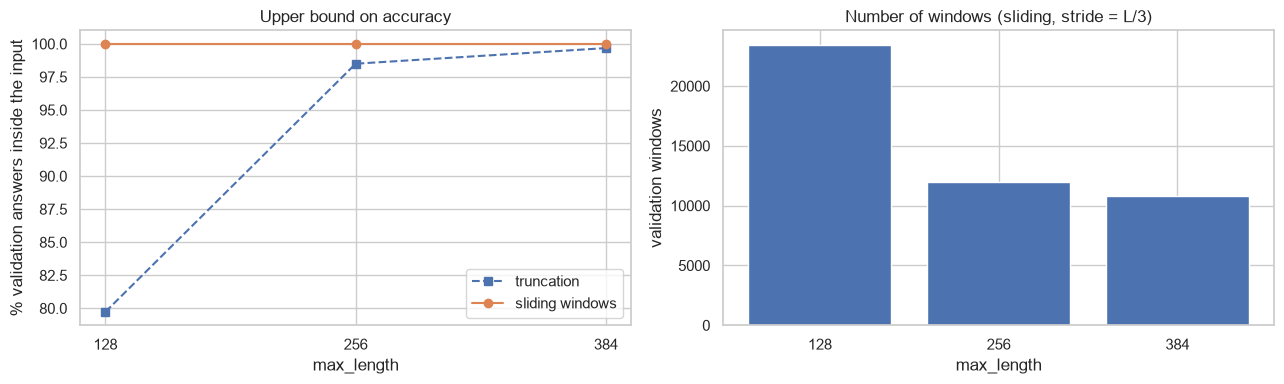

In [17]:
SEQ_SETTINGS = [(128, 42), (256, 85), (384, 128)]
rows = []
for L, stride in SEQ_SETTINGS:
    fw, sw = eqa.prepare_features(val_df, tokenizer, L, stride, sliding_window=True)
    ft, st = eqa.prepare_features(val_df, tokenizer, L, sliding_window=False)
    rows.append({"max_length": L, "doc_stride": stride, "windows (sliding)": sw["features"],
                 "windows per example": sw["features"] / len(val_df),
                 "mean tokens per window": np.mean([len(x) for x in fw["input_ids"]]),
                 "answers reachable – truncation (%)": 100 * st["examples_with_answer_in_some_window"] / len(val_df),
                 "answers reachable – sliding windows (%)": 100 * sw["examples_with_answer_in_some_window"] / len(val_df)})
seq_preview = pd.DataFrame(rows).round(2)
display(seq_preview)
seq_preview.to_csv(eqa.PATHS.results / "seq_len_preprocessing_preview.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(seq_preview["max_length"], seq_preview["answers reachable – truncation (%)"], "s--", label="truncation")
axes[0].plot(seq_preview["max_length"], seq_preview["answers reachable – sliding windows (%)"], "o-", label="sliding windows")
axes[0].set_xlabel("max_length"); axes[0].set_ylabel("% validation answers inside the input"); axes[0].legend()
axes[0].set_title("Upper bound on accuracy"); axes[0].set_xticks(seq_preview["max_length"])
axes[1].bar(seq_preview["max_length"].astype(str), seq_preview["windows (sliding)"])
axes[1].set_xlabel("max_length"); axes[1].set_ylabel("validation windows"); axes[1].set_title("Number of windows (sliding, stride = L/3)")
eqa.savefig("01_truncation_vs_windows_preview")

### 4.4 Batching: dynamic padding and length-grouped batches
Features are stored **unpadded**. `collate` pads each batch only to its longest sequence and builds the attention mask. For training, `LengthGroupedBatchSampler` puts sequences of similar length into the same batch (shuffle → chunks of 50 batches → sort each chunk by length → shuffle the batches), so very little computation is spent on padding. Padded positions are masked, so the loss is unchanged.

In [18]:
eqa.show_source(eqa.collate, eqa.LengthGroupedBatchSampler)
ds = eqa.QAFeatureDataset(train_win)
batch = eqa.collate([ds[i] for i in range(4)])
print({k: tuple(v.shape) for k, v in batch.items()})
r = int(batch["attention_mask"].sum(1).argmin())
print(f"shortest sequence in this batch has {int(batch['attention_mask'][r].sum())} tokens; "
      f"its attention_mask ends with {batch['attention_mask'][r].tolist()[-12:]} (1 = token, 0 = padding)")
lens = np.array([len(x) for x in train_win["input_ids"]])
sampler = eqa.LengthGroupedBatchSampler(lens, batch_size=16)
pad_random = np.mean([lens[np.random.default_rng(0).choice(len(lens), 16)].max() for _ in range(500)])
pad_grouped = np.mean([lens[b].max() for b in list(iter(sampler))[:500]])
print(f"Mean / max sequence length: {lens.mean():.0f} / {lens.max()} tokens")
print(f"Tokens computed per sequence: padding to 384 -> 384 | random batches -> {pad_random:.0f} | length-grouped -> {pad_grouped:.0f}")

```python
def collate(batch, pad_id: int = 0):
    """Dynamic padding: pad to the longest sequence in the batch and build the attention mask (1 = token, 0 = pad)."""
    B, L = len(batch), max(len(b["input_ids"]) for b in batch)
    input_ids = torch.full((B, L), pad_id, dtype=torch.long)
    token_type_ids = torch.zeros((B, L), dtype=torch.long)
    attention_mask = torch.zeros((B, L), dtype=torch.long)
    for i, b in enumerate(batch):
        n = len(b["input_ids"])
        input_ids[i, :n] = torch.tensor(b["input_ids"])
        token_type_ids[i, :n] = torch.tensor(b["token_type_ids"])
        attention_mask[i, :n] = 1
    return {"input_ids": input_ids, "token_type_ids": token_type_ids, "attention_mask": attention_mask,
            "start_positions": torch.tensor([b["start_positions"] for b in batch]),
            "end_positions": torch.tensor([b["end_positions"] for b in batch]),
            "feature_idx": torch.tensor([b["feature_idx"] for b in batch])}

```

```python
class LengthGroupedBatchSampler(Sampler):
    """Random batches of similar-length sequences: shuffle -> chunks of 50 batches -> sort chunk by length ->
    cut into batches -> shuffle batches. Less padding, same optimisation problem."""

    def __init__(self, lengths, batch_size, chunk_batches=50, seed=SEED):
        self.lengths, self.bs, self.seed, self.epoch = np.asarray(lengths), batch_size, seed, 0
        self.chunk = batch_size * chunk_batches

    def set_epoch(self, epoch):
        self.epoch = epoch

    def __iter__(self):
        rng = np.random.default_rng(self.seed + self.epoch)
        perm = rng.permutation(len(self.lengths))
        batches = []
        for c in range(0, len(perm), self.chunk):
            chunk = perm[c:c + self.chunk]
            chunk = chunk[np.argsort(-self.lengths[chunk], kind="stable")]
            batches += [chunk[i:i + self.bs].tolist() for i in range(0, len(chunk), self.bs)]
        for b in rng.permutation(len(batches)):
            yield batches[b]

    def __len__(self):
        full, rem = divmod(len(self.lengths), self.chunk)
        return full * math.ceil(self.chunk / self.bs) + math.ceil(rem / self.bs)

```

{'input_ids': (4, 176), 'token_type_ids': (4, 176), 'attention_mask': (4, 176), 'start_positions': (4,), 'end_positions': (4,), 'feature_idx': (4,)}
shortest sequence in this batch has 170 tokens; its attention_mask ends with [1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0] (1 = token, 0 = padding)
Mean / max sequence length: 171 / 384 tokens
Tokens computed per sequence: padding to 384 -> 384 | random batches -> 294 | length-grouped -> 168


## 5. Evaluation metrics and end-to-end pipeline check
### 5.1 Exact Match and F1 (official SQuAD v1.1 definitions)
Both metrics first **normalise** prediction and reference: lower-case, remove punctuation, remove the articles *a/an/the*, collapse whitespace. With $G$ the set of reference answers of a question:

* **Exact Match:** $\text{EM} = \max_{g\in G} \mathbb{1}\left[\operatorname{norm}(\hat a) = \operatorname{norm}(g)\right]$
* **Token-level F1:** with $\text{common} = |\operatorname{tok}(\hat a) \cap \operatorname{tok}(g)|$ (multiset intersection), $P = \frac{\text{common}}{|\operatorname{tok}(\hat a)|}$, $R = \frac{\text{common}}{|\operatorname{tok}(g)|}$, $F_1 = \frac{2PR}{P+R}$, and $\text{F1} = \max_{g\in G} F_1(\hat a, g)$.

Both are averaged over questions and reported in %. EM rewards exact boundaries; F1 gives partial credit for overlapping spans, so **F1 − EM measures boundary errors**. They are *not* token-classification accuracy: they compare answer strings.

In [19]:
eqa.show_source(eqa.normalize_answer, eqa.f1_score, eqa.squad_evaluate)
tests = [("The  Denver Broncos!", "Denver Broncos", 1.0, 1.0), ("Denver Broncos team", "Denver Broncos", 0.0, 0.8),
         ("Carolina Panthers", "Denver Broncos", 0.0, 0.0), ("in 1936", "1936", 0.0, 2 / 3)]
for pred, gold, em, f1 in tests:
    got_em, got_f1 = eqa.exact_match_score(pred, gold), eqa.f1_score(pred, gold)
    assert got_em == em and abs(got_f1 - f1) < 1e-9, (pred, gold, got_em, got_f1)
    print(f"pred={pred!r:24} gold={gold!r:18} EM={got_em:.0f}  F1={got_f1:.3f}")
print("Metric unit tests passed.")

```python
def normalize_answer(s: str) -> str:
    """Lower-case, remove punctuation, remove articles (a/an/the), collapse whitespace."""
    s = s.lower()
    s = "".join(ch for ch in s if ch not in set(string.punctuation))
    s = re.sub(r"\b(a|an|the)\b", " ", s)
    return " ".join(s.split())

```

```python
def f1_score(prediction: str, ground_truth: str) -> float:
    pred_tokens, gold_tokens = normalize_answer(prediction).split(), normalize_answer(ground_truth).split()
    common = collections.Counter(pred_tokens) & collections.Counter(gold_tokens)
    num_same = sum(common.values())
    if num_same == 0:
        return 0.0
    precision, recall = num_same / len(pred_tokens), num_same / len(gold_tokens)
    return 2 * precision * recall / (precision + recall)

```

```python
def squad_evaluate(predictions: dict, df: pd.DataFrame):
    """Mean over questions of max-over-references EM and F1 (in %). Also returns per-question arrays."""
    ems, f1s = [], []
    for qid, golds in zip(df["id"], df["answer_texts"]):
        pred = predictions.get(qid, "")
        ems.append(metric_max_over_ground_truths(exact_match_score, pred, golds))
        f1s.append(metric_max_over_ground_truths(f1_score, pred, golds))
    ems, f1s = np.array(ems), np.array(f1s)
    return {"exact_match": 100 * ems.mean(), "f1": 100 * f1s.mean()}, ems, f1s

```

pred='The  Denver Broncos!'   gold='Denver Broncos'   EM=1  F1=1.000
pred='Denver Broncos team'    gold='Denver Broncos'   EM=0  F1=0.800
pred='Carolina Panthers'      gold='Denver Broncos'   EM=0  F1=0.000
pred='in 1936'                gold='1936'             EM=0  F1=0.667
Metric unit tests passed.


### 5.2 Pipeline check with an "oracle" model
To verify that preprocessing, the label alignment, the span search and the character-offset extraction are correct *before* training anything, we feed `eqa.postprocess_predictions` with "oracle" logits that put all probability on the gold labels. With sliding windows this must give ≈100 EM; with truncation it can only reach the share of answers that survive the cut. This is the **upper bound** of each input strategy.

In [20]:
eqa.show_source(eqa.postprocess_predictions)
rows = []
for L, stride in SEQ_SETTINGS:
    for mode in ("sliding windows", "truncation"):
        feats, _ = eqa.prepare_features(val_df, tokenizer, L, stride, sliding_window=(mode == "sliding windows"), keep_offsets=True)
        sl, el = eqa.oracle_logits(feats)
        preds, details = eqa.postprocess_predictions(val_df, feats, sl, el)
        scores, ems, f1s = eqa.squad_evaluate(preds, val_df)
        ok = details[details["start_char"] >= 0]
        assert all(val_df["context"].iloc[r.example_idx][r.start_char:r.end_char] == r.prediction for r in ok.itertuples())
        rows.append({"max_length": L, "input strategy": mode, "oracle EM": scores["exact_match"], "oracle F1": scores["f1"]})
oracle = pd.DataFrame(rows).round(2)
display(oracle)
oracle.to_csv(eqa.PATHS.results / "oracle_upper_bounds.csv", index=False)
print("Every predicted answer is an exact substring of its original context (assert passed).")

```python
def postprocess_predictions(df, feats, start_logits, end_logits, n_best=None, max_answer_len=None):
    """Best valid span per example over all its windows; the answer is sliced from the ORIGINAL context.

    Valid span: start <= end, length <= max_answer_len tokens, both tokens inside the context (offset not None).
    Score = start_logit + end_logit. Confidence = P_start * P_end (softmax over the winning window's context tokens).
    """
    n_best = n_best or CFG["n_best"]
    max_answer_len = max_answer_len or CFG["max_answer_length"]
    by_example = collections.defaultdict(list)
    for f, ex in enumerate(feats["example_idx"]):
        by_example[ex].append(f)
    ids, contexts = df["id"].tolist(), df["context"].tolist()
    predictions, details = {}, []
    for ex in range(len(df)):
        best = None
        for f in by_example.get(ex, []):
            sl, el, offs = start_logits[f], end_logits[f], feats["offset_mapping"][f]
            for s in np.argsort(sl)[::-1][:n_best]:
                if offs[s] is None:
                    continue
                for e in np.argsort(el)[::-1][:n_best]:
                    if offs[e] is None or e < s or e - s + 1 > max_answer_len:
                        continue
                    score = sl[s] + el[e]
                    if best is None or score > best["score"]:
                        best = {"score": float(score), "feature": f, "start_token": int(s), "end_token": int(e)}
        rec = {"id": ids[ex], "example_idx": ex}
        if best is None:
            rec.update(prediction="", score=float("nan"), confidence=0.0, start_char=-1, end_char=-1,
                       start_token=-1, end_token=-1, window=-1)
        else:
            f, offs = best["feature"], feats["offset_mapping"][best["feature"]]
            ctx_mask = np.array([o is not None for o in offs])
            p_s = masked_softmax(np.asarray(start_logits[f], dtype=np.float64), ctx_mask)[best["start_token"]]
            p_e = masked_softmax(np.asarray(end_logits[f], dtype=np.float64), ctx_mask)[best["end_token"]]
            sc, ec = offs[best["start_token"]][0], offs[best["end_token"]][1]
            rec.update(prediction=contexts[ex][sc:ec], score=best["score"], confidence=float(p_s * p_e),
                       start_char=sc, end_char=ec, start_token=best["start_token"], end_token=best["end_token"],
                       window=feats["window_idx"][f])
        predictions[rec["id"]] = rec["prediction"]
        details.append(rec)
    return predictions, pd.DataFrame(details)

```

,max_length,input strategy,oracle EM,oracle F1
0,128,sliding windows,99.70,99.76
1,128,truncation,79.49,79.91
2,256,sliding windows,99.70,99.76
3,256,truncation,98.22,98.30
4,384,sliding windows,99.70,99.78
5,384,truncation,99.39,99.48


Every predicted answer is an exact substring of its original context (assert passed).


## 6. Summary
* SQuAD 1.1 is loaded (87,599 / 10,570 questions), clean, and explored. Figures are saved in `results/graphs/01_*.png`, and key statistics in `results/eda_summary.json`.
* The preprocessing maps character answers to token labels through the offset mapping. Label correctness is verified on every training window, and the remaining mismatches are annotation errors.
* Both input strategies (truncation for A2, sliding windows for A3) are implemented. The oracle check shows that the pipeline is lossless with windows, and quantifies the accuracy ceiling of truncation at each length.
* Metrics follow the official SQuAD v1.1 script and pass unit tests.

**Next:** `02_Transformer_From_Scratch.ipynb` (Approach A1).